<a href="https://colab.research.google.com/github/mafdhalrzy/ButterflyImageClassification/blob/main/ButterflyImageClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Library yang sering digunakan
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm as tq

In [2]:
# Libraries untuk pemrosesan data gambar
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
# Libraries untuk pembangunan model
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import Model, layers, Input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.regularizers import l2

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Mencetak versi TensorFlow yang sedang digunakan
print(tf.__version__)

2.21.0


In [6]:
# Import module yang disediakan google colab untuk kebutuhan upload file

from google.colab import files
files.upload()

Saving access_token to access_token


{'access_token': b'KGAT_c35566f809fad7b0fe8fbad7c0573a36'}

In [7]:
!mkdir -p ~/.kaggle
!cp access_token ~/.kaggle/
!chmod 600 ~/.kaggle/access_token

!kaggle datasets download -d phucthaiv02/butterfly-image-classification
!unzip -q butterfly-image-classification.zip -d ./dataset_butterfly

Dataset URL: https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification
License(s): CC0-1.0
100% 226M/226M [00:12<00:00, 18.8MB/s]



In [8]:
csv_path = "./dataset_butterfly/Training_set.csv"
df_train = pd.read_csv(csv_path)

In [9]:
print("5 Data Teratas:")
print(df_train.head())

5 Data Teratas:
      filename                     label
0  Image_1.jpg          SOUTHERN DOGFACE
1  Image_2.jpg                    ADONIS
2  Image_3.jpg            BROWN SIPROETA
3  Image_4.jpg                   MONARCH
4  Image_5.jpg  GREEN CELLED CATTLEHEART


In [10]:
source_dir = "./dataset_butterfly/train"
combined_dir = "butterfly/dataset"

In [11]:
# Buat direktori baru untuk dataset gabungan
os.makedirs(combined_dir, exist_ok=True)

In [12]:
print("\nMemulai proses penataan dataset...")
for index, row in tq(df_train.iterrows(), total=len(df_train)):
    # Ambil nama file gambar dan nama label kelas dari baris tabel
    # Petunjuk: Isi ____ dengan nama kolom yang sesuai pada Training_set.csv
    file_name = row['filename']
    label_name = row['label']

    # Menentukan path folder sub-kelas (contoh: butterfly/dataset/ADONIS)
    class_dir = os.path.join(combined_dir, label_name)
    os.makedirs(class_dir, exist_ok=True)

    # Menentukan path file sumber dan tujuan
    src_file = os.path.join(source_dir, file_name)
    dst_file = os.path.join(class_dir, file_name)

    # Salin file jika file di folder asal memang ada
    if os.path.exists(src_file):
        shutil.copy(src_file, dst_file)

print("\nPenataan dataset selesai!")


Memulai proses penataan dataset...


  0%|          | 0/6499 [00:00<?, ?it/s]


Penataan dataset selesai!


In [13]:
butterfly_images = {}
classes = os.listdir(combined_dir)

for c in classes:
    class_folder = os.path.join(combined_dir, c)
    if os.path.isdir(class_folder):
        butterfly_images[c] = os.listdir(class_folder)

print(f"Total kelas/spesies yang ditemukan: {len(butterfly_images)} kelas")

Total kelas/spesies yang ditemukan: 75 kelas


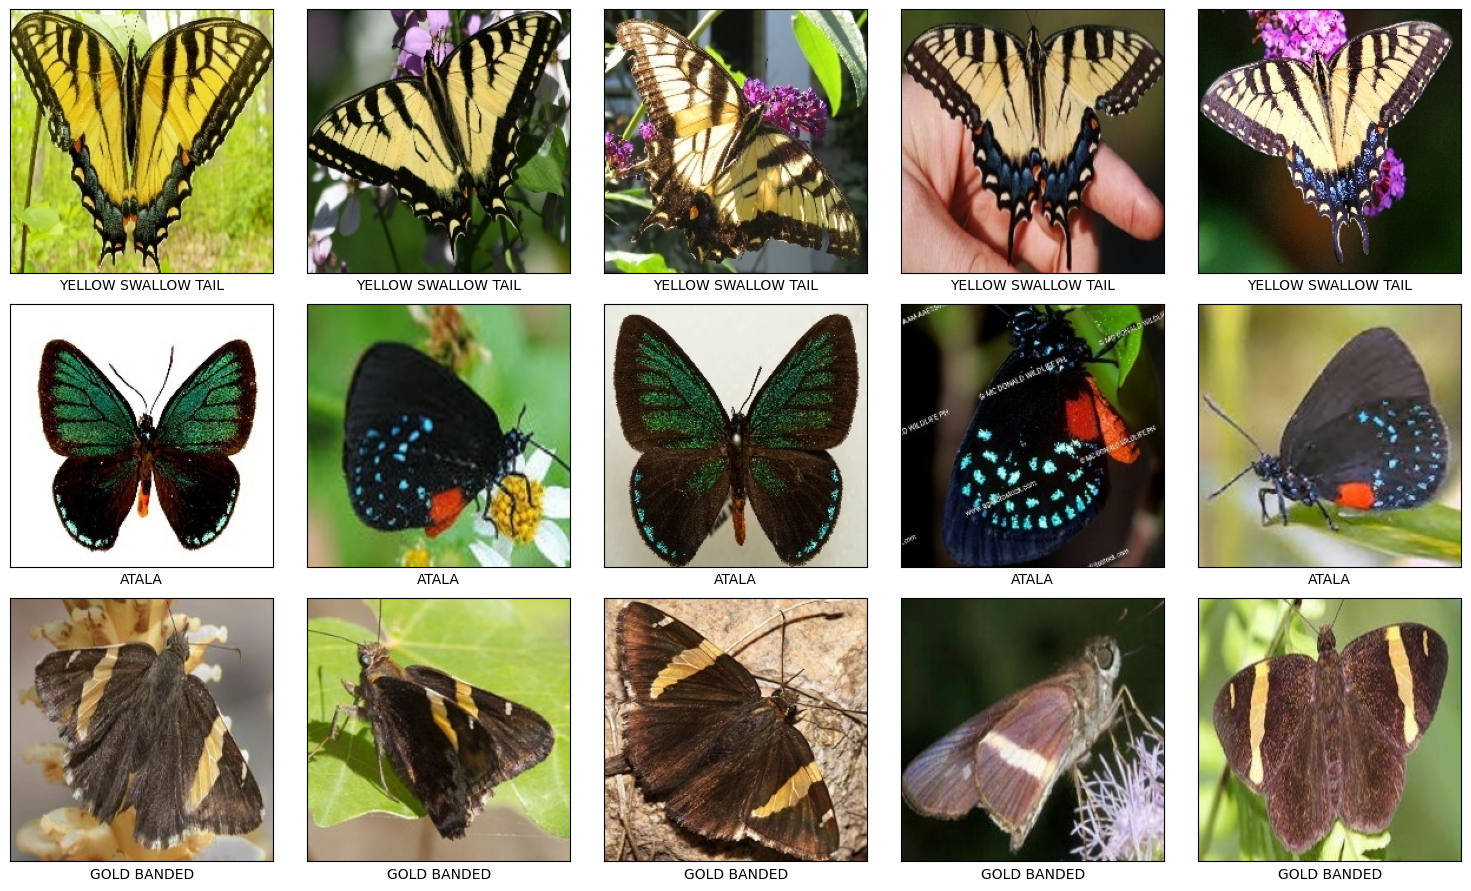

In [14]:
selected_classes = random.sample(list(butterfly_images.keys()), 3)

# Membuat grid visualisasi: 3 baris (kelas) x 5 kolom (sampel gambar)
fig, axs = plt.subplots(len(selected_classes), 5, figsize=(15, 9))

for i, class_name in enumerate(selected_classes):
    # Mengambil 5 gambar acak dari kelas tersebut
    # Petunjuk: Pilih array daftar gambar dari kelas yang sedang aktif di kamus
    sample_images = np.random.choice(butterfly_images[class_name], 5, replace=False)

    for j, image_name in enumerate(sample_images):
        img_path = os.path.join(combined_dir, class_name, image_name)

        # Buka gambar menggunakan PIL Image
        img = Image.open(img_path)

        # Petunjuk:
        # Jika ingin tetap berwarna (RGB), gunakan .convert("RGB")
        # Jika ingin grayscale, gunakan .convert("L")
        img = img.convert("RGB")

        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

fig.tight_layout()
plt.show()

In [15]:
file_name = []
labels = []
full_path = []

# 2. Menelusuri seluruh direktori dan mengumpulkan data
for path, subdirs, files in os.walk(combined_dir):
    for name in files:
        full_path.append(os.path.join(path, name))
        # Mengambil nama folder sebagai label
        # (path.split('/')[-1] mengambil elemen terakhir dari path folder)
        labels.append(path.split('/')[-1])
        file_name.append(name)

                                          path       file_name      labels
0  butterfly/dataset/ORANGE TIP/Image_2585.jpg  Image_2585.jpg  ORANGE TIP
1  butterfly/dataset/ORANGE TIP/Image_5036.jpg  Image_5036.jpg  ORANGE TIP
2  butterfly/dataset/ORANGE TIP/Image_4886.jpg  Image_4886.jpg  ORANGE TIP
3  butterfly/dataset/ORANGE TIP/Image_4151.jpg  Image_4151.jpg  ORANGE TIP
4   butterfly/dataset/ORANGE TIP/Image_150.jpg   Image_150.jpg  ORANGE TIP

Statistik jumlah gambar per kelas:
count     75.000000
mean      86.653333
std        9.267049
min       71.000000
25%       81.000000
50%       86.000000
75%       92.000000
max      131.000000
Name: count, dtype: float64




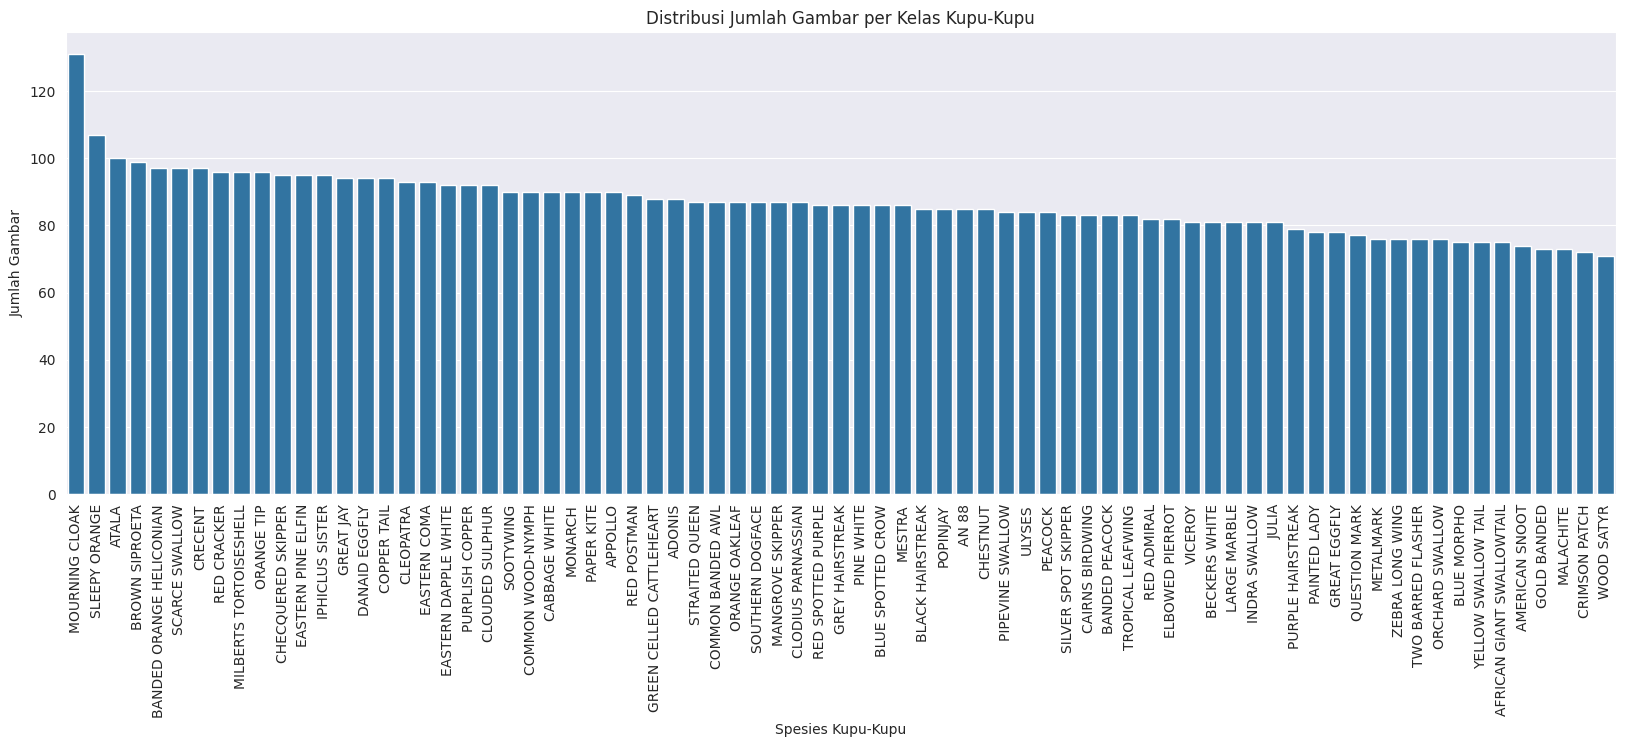

In [16]:
distribution_train = pd.DataFrame({"path": full_path, "file_name": file_name, "labels": labels})

# Menampilkan 5 baris pertama DataFrame
print(distribution_train.head())

# 4. Memeriksa ringkasan statistik jumlah gambar per kelas
print("\nStatistik jumlah gambar per kelas:")
print(distribution_train['labels'].value_counts().describe())
print("\n")

# 5. Plot distribusi gambar menggunakan Seaborn
plt.figure(figsize=(20, 6)) # Ukuran diperlebar agar 75 kelas muat
sns.set_style("darkgrid")

# Petunjuk: Isi data yang ingin dihitung frekuensinya (kolom label)
sns.countplot(data=distribution_train, x='labels', order=distribution_train['labels'].value_counts().index)

# Memutar teks sumbu X sebesar 90 derajat agar terbaca vertikal
plt.xticks(rotation=90)
plt.title("Distribusi Jumlah Gambar per Kelas Kupu-Kupu")
plt.xlabel("Spesies Kupu-Kupu")
plt.ylabel("Jumlah Gambar")
plt.show()

In [17]:
df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
ADONIS,88
AFRICAN GIANT SWALLOWTAIL,75
AMERICAN SNOOT,74
AN 88,85
APPOLLO,90
...,...
ULYSES,84
VICEROY,81
WOOD SATYR,71


In [18]:
# 2. Pemisahan Data (Two-step train_test_split)
X = df['path']
y = df['labels']

# Split 1: Pisahkan 80% Train dan 20% Sisa (Val + Test)
# Petunjuk: Tentukan test_size untuk menyisakan 20% data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=300, stratify=y
)

# Split 2: Bagi data sisa 20% menjadi dua sama rata (10% Val dan 10% Test)
# Petunjuk: Agar 20% terbagi rata (masing-masing 10%), berapa test_size dari data sisa tersebut? (50% = 0.5)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=300, stratify=y_temp
)

In [19]:
# 3. Menyatukan ke dalam DataFrame masing-masing
df_tr = pd.DataFrame({'path': X_train, 'labels': y_train, 'set': 'train'})
df_val = pd.DataFrame({'path': X_val, 'labels': y_val, 'set': 'val'})
df_te = pd.DataFrame({'path': X_test, 'labels': y_test, 'set': 'test'})

In [20]:
# Gabungkan ketiga dataframe
# Petunjuk: Masukkan df_tr, df_val, dan df_te ke dalam list pd.concat
df_all = pd.concat([df_tr, df_val, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

# Cek sampel data
print(df_all.sample(5))

# Membuat variabel Dataset, tempat menampung data yang telah dilakukan pembagian data training dan testing
target_split_dir = "dataset_final"


set   labels                   
test  ADONIS                       9
      AFRICAN GIANT SWALLOWTAIL    8
      AMERICAN SNOOT               7
      AN 88                        9
      APPOLLO                      9
                                  ..
val   ULYSES                       8
      VICEROY                      8
      WOOD SATYR                   7
      YELLOW SWALLOW TAIL          7
      ZEBRA LONG WING              7
Length: 225, dtype: int64 


                                                   path  \
5725  butterfly/dataset/BANDED ORANGE HELICONIAN/Ima...   
5799          butterfly/dataset/CHESTNUT/Image_4463.jpg   
563   butterfly/dataset/AFRICAN GIANT SWALLOWTAIL/Im...   
4887           butterfly/dataset/CRECENT/Image_3767.jpg   
2363      butterfly/dataset/SLEEPY ORANGE/Image_143.jpg   

                         labels    set  
5725   BANDED ORANGE HELICONIAN    val  
5799                   CHESTNUT    val  
563   AFRICAN GIANT SWALLOWTAIL  train  
4887        

In [21]:
print("\nMemindahkan gambar ke struktur folder train/val/test...")
for index, row in tq(df_all.iterrows(), total=len(df_all)):
    file_path = row['path']
    set_name = row['set']
    label_name = row['labels']

    # Buat direktori tujuan: dataset_final/<set>/<label>
    dest_dir = os.path.join(target_split_dir, set_name, label_name)
    os.makedirs(dest_dir, exist_ok=True)

    # Ambil nama file asli dari path
    destination_file_name = os.path.basename(file_path)

    # Salin file ke folder tujuan dengan nama aslinya
    dest_file = os.path.join(dest_dir, destination_file_name)
    if not os.path.exists(dest_file):
        shutil.copy2(file_path, dest_file)

print("\nData Splitting 3-bagian selesai dengan sukses!")


Memindahkan gambar ke struktur folder train/val/test...


  0%|          | 0/6499 [00:00<?, ?it/s]


Data Splitting 3-bagian selesai dengan sukses!


In [22]:
# Menentukan path direktori data train, val, dan test
TRAIN_DIR = "dataset_final/train"
VAL_DIR   = "dataset_final/val"
TEST_DIR  = "dataset_final/test"

# Menghitung total gambar di masing-masing direktori (75 kelas)
total_train = sum([len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in os.listdir(TRAIN_DIR)])
total_val   = sum([len(os.listdir(os.path.join(VAL_DIR, c))) for c in os.listdir(VAL_DIR)])
total_test  = sum([len(os.listdir(os.path.join(TEST_DIR, c))) for c in os.listdir(TEST_DIR)])

print("Total images in training set   : ", total_train)
print("Total images in validation set : ", total_val)
print("Total images in test set       : ", total_test)

Total images in training set   :  5199
Total images in validation set :  650
Total images in test set       :  650


In [37]:
# 2. Membuat Objek ImageDataGenerator
# Untuk Data Latih: Rescale + Augmentasi (mencegah overfitting)
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    shear_range=0.2,
    fill_mode='nearest'
)

# Untuk Data Validasi & Uji: HANYA RESCALE (evaluasi jujur tanpa manipulasi)
val_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)
test_datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input)

# 3. Menghubungkan Generator dengan Direktori Fisik
# Generator Data Latih
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(150, 150),
    batch_size=32,
    color_mode="rgb",       # Petunjuk: Pilih "rgb" atau "grayscale"
    class_mode="categorical",       # Petunjuk: Pilih "categorical" atau "binary"
    shuffle=True
)

# Generator Data Validasi
validation_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(150, 150),
    batch_size=32,
    color_mode="rgb",       # Petunjuk: Samakan dengan train_generator
    class_mode="categorical",       # Petunjuk: Samakan dengan train_generator
    shuffle=False
)

# Generator Data Uji (Test)
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(150, 150),
    batch_size=1,            # 1 per 1 untuk pengujian mandiri
    color_mode="rgb",       # Petunjuk: Samakan dengan train_generator
    class_mode="categorical",       # Petunjuk: Samakan dengan train_generator
    shuffle=False
)

Found 5199 images belonging to 75 classes.
Found 650 images belonging to 75 classes.
Found 650 images belonging to 75 classes.


In [38]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, BatchNormalization, Flatten, Dense, Dropout
from tensorflow.keras.applications import MobileNetV2

# 1. Bersihkan sesi sebelumnya
tf.keras.backend.clear_session()

# 2. Memuat Base Model MobileNetV2 (Tanpa layer output bawaan)
base_model = MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,       # Membuang layer klasifikasi bawaan ImageNet
    weights='imagenet'       # Menggunakan bobot pintar dari ImageNet
)

# Membuka kunci pelatihan pada base_model untuk Fine-Tuning
base_model.trainable = False

# 3. Membangun Model Sequential (Memenuhi Kriteria 4)
# Petunjuk: Inisialisasi model Sequential
model = Sequential()

# Menambahkan Input Layer eksplisit
model.add(layers.Input(shape=(150, 150, 3)))

# Menambahkan Base Model ke dalam Sequential
model.add(base_model)

# Menambahkan Conv2D dan Pooling Layer milik kita sendiri (Syarat Kriteria 4)
# Petunjuk: Gunakan ukuran kernel (3, 3) pada Conv2D dan pool_size (2, 2) pada MaxPool2D
model.add(Conv2D(64, (3, 3), padding='same', activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2)))

# Perataan dan Fully Connected Layer
model.add(GlobalAveragePooling2D())
model.add(Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)))
model.add(BatchNormalization())
model.add(Dropout(0.5))

# Output Layer untuk 75 Spesies Kupu-Kupu
# Petunjuk: Isi jumlah kelas dan fungsi aktivasi multikelas
model.add(Dense(75, activation='softmax'))

# 4. Kompilasi Model
# Gunakan learning_rate kecil (0.0001) karena kita melakukan fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

model.summary()

/tmp/ipykernel_1165/95741585.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 5, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 5, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,032,523 (11.57 MB)

 Trainable params: 773,899 (2.95 MB)

 Non-trainable params: 2,258,624 (8.62 MB)

In [39]:
import time

# Callback penghenti otomatis saat Train & Val mencapai >= 85%
class TargetCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        acc = logs.get('accuracy', 0)
        val_acc = logs.get('val_accuracy', 0)
        if acc >= 0.85 and val_acc >= 0.85:
            print(f"\n[INFO] Target >= 85% tercapai pada epoch {epoch+1}! (Train: {acc:.4f}, Val: {val_acc:.4f})")
            self.model.stop_training = True

# Callback tambahan: Menurunkan learning rate otomatis jika val_loss melambat
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [40]:
import time

print("--- Memulai Fase 1: Warm-up Head Model (10 Epoch) ---")
start_time = time.time()

# 3. Eksekusi Pelatihan Fase 1
history_phase1 = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator,
    callbacks=[TargetCallback()] # reduce_lr biasanya disimpan untuk Fase 2
)

print(f"Fase 1 selesai dalam waktu: {(time.time() - start_time)/60:.2f} menit")

--- Memulai Fase 1: Warm-up Head Model (10 Epoch) ---
Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 54s 262ms/step - accuracy: 0.3195 - loss: 5.3094 - val_accuracy: 0.6400 - val_loss: 3.8945
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 191ms/step - accuracy: 0.6193 - loss: 3.5923 - val_accuracy: 0.7262 - val_loss: 3.1242
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 196ms/step - accuracy: 0.6974 - loss: 3.0387 - val_accuracy: 0.7554 - val_loss: 2.7627
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.7171 - loss: 2.7683 - val_accuracy: 0.7015 - val_loss: 2.7709
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 189ms/step - accuracy: 0.7357 - loss: 2.6131 - val_accuracy: 0.7692 - val_loss: 2.4702
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 199ms/step - accuracy: 0.7434 - loss: 2.5010 - val_accuracy: 0.7508 - val_loss: 2.4931
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 191ms/step - accuracy: 0.7511 - loss: 2.4112 - val_accuracy: 0.7323 - val_loss: 2.4416
Epoch 8/10
163/163 ━━━━━━━━━━

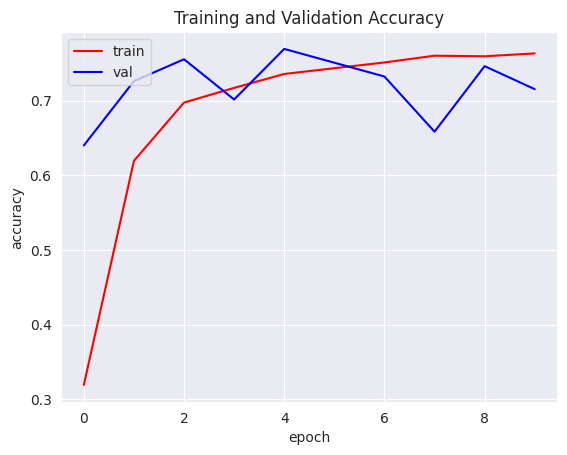

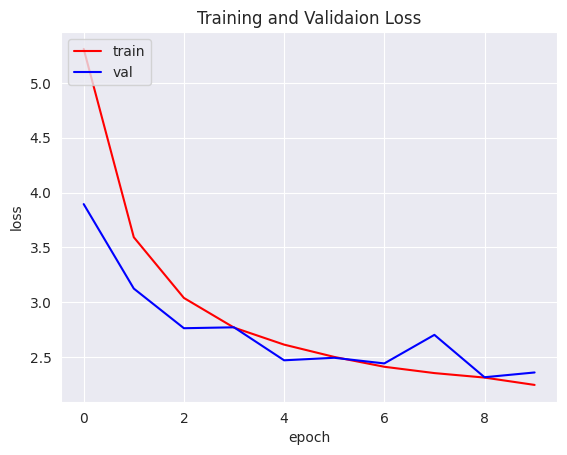

In [41]:
acc = history_phase1.history['accuracy']
val_acc = history_phase1.history['val_accuracy']
loss = history_phase1.history['loss']
val_loss = history_phase1.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

print("\n")

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

In [42]:
# 4. Buka gembok seluruh base_model untuk persiapan Fine-Tuning
base_model.trainable = True

# 5. Bekukan kembali 100 layer pertama agar fondasi fitur bawaan (ImageNet) tidak hancur
for layer in base_model.layers[:100]:
    layer.trainable = False

# 6. WAJIB KOMPILASI ULANG! Ini krusial agar Keras membaca status trainable yang baru.
# Gunakan learning rate yang sangat kecil (5e-5) agar bobot tidak melompat.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

print("\nStatus Model Fase 2 (Sebagian Base Model & Head Trainable):")
model.summary()


Status Model Fase 2 (Sebagian Base Model & Head Trainable):


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 5, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 5, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,032,523 (11.57 MB)

 Trainable params: 2,635,339 (10.05 MB)

 Non-trainable params: 397,184 (1.52 MB)

In [43]:
print("Memulai pelatihan model Hybrid CNN...")
start_time = time.time()

# Petunjuk: Masukkan generator train dan generator validasi
history_phase2 = model.fit(
    train_generator,
    epochs=25,
    validation_data=validation_generator,
    # ReduceLROnPlateau sangat cocok bekerja di fase ini
    callbacks=[TargetCallback(), reduce_lr]
)

print(f"Pelatihan selesai dalam waktu: {(time.time() - start_time)/60:.2f} menit")

Memulai pelatihan model Hybrid CNN...
Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 68s 296ms/step - accuracy: 0.6934 - loss: 2.4819 - val_accuracy: 0.8108 - val_loss: 2.2581 - learning_rate: 5.0000e-05
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 198ms/step - accuracy: 0.8046 - loss: 2.1263 - val_accuracy: 0.8338 - val_loss: 2.1835 - learning_rate: 5.0000e-05
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 195ms/step - accuracy: 0.8563 - loss: 1.9650 - val_accuracy: 0.8477 - val_loss: 2.0701 - learning_rate: 5.0000e-05
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8795 - loss: 1.8822
[INFO] Target >= 85% tercapai pada epoch 4! (Train: 0.8725, Val: 0.8523)
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 195ms/step - accuracy: 0.8725 - loss: 1.8762 - val_accuracy: 0.8523 - val_loss: 1.9640 - learning_rate: 5.0000e-05
Pelatihan selesai dalam waktu: 2.75 menit


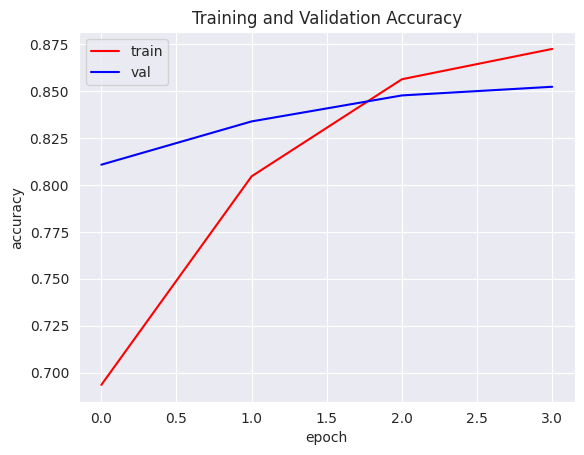

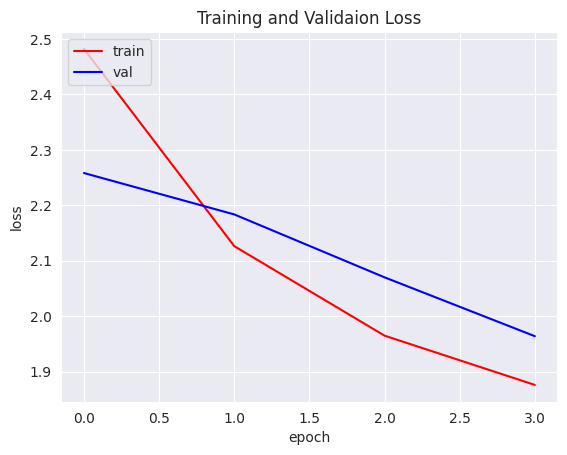

In [44]:
acc = history_phase2.history['accuracy']
val_acc = history_phase2.history['val_accuracy']
loss = history_phase2.history['loss']
val_loss = history_phase2.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

print("\n")

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

650/650 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step


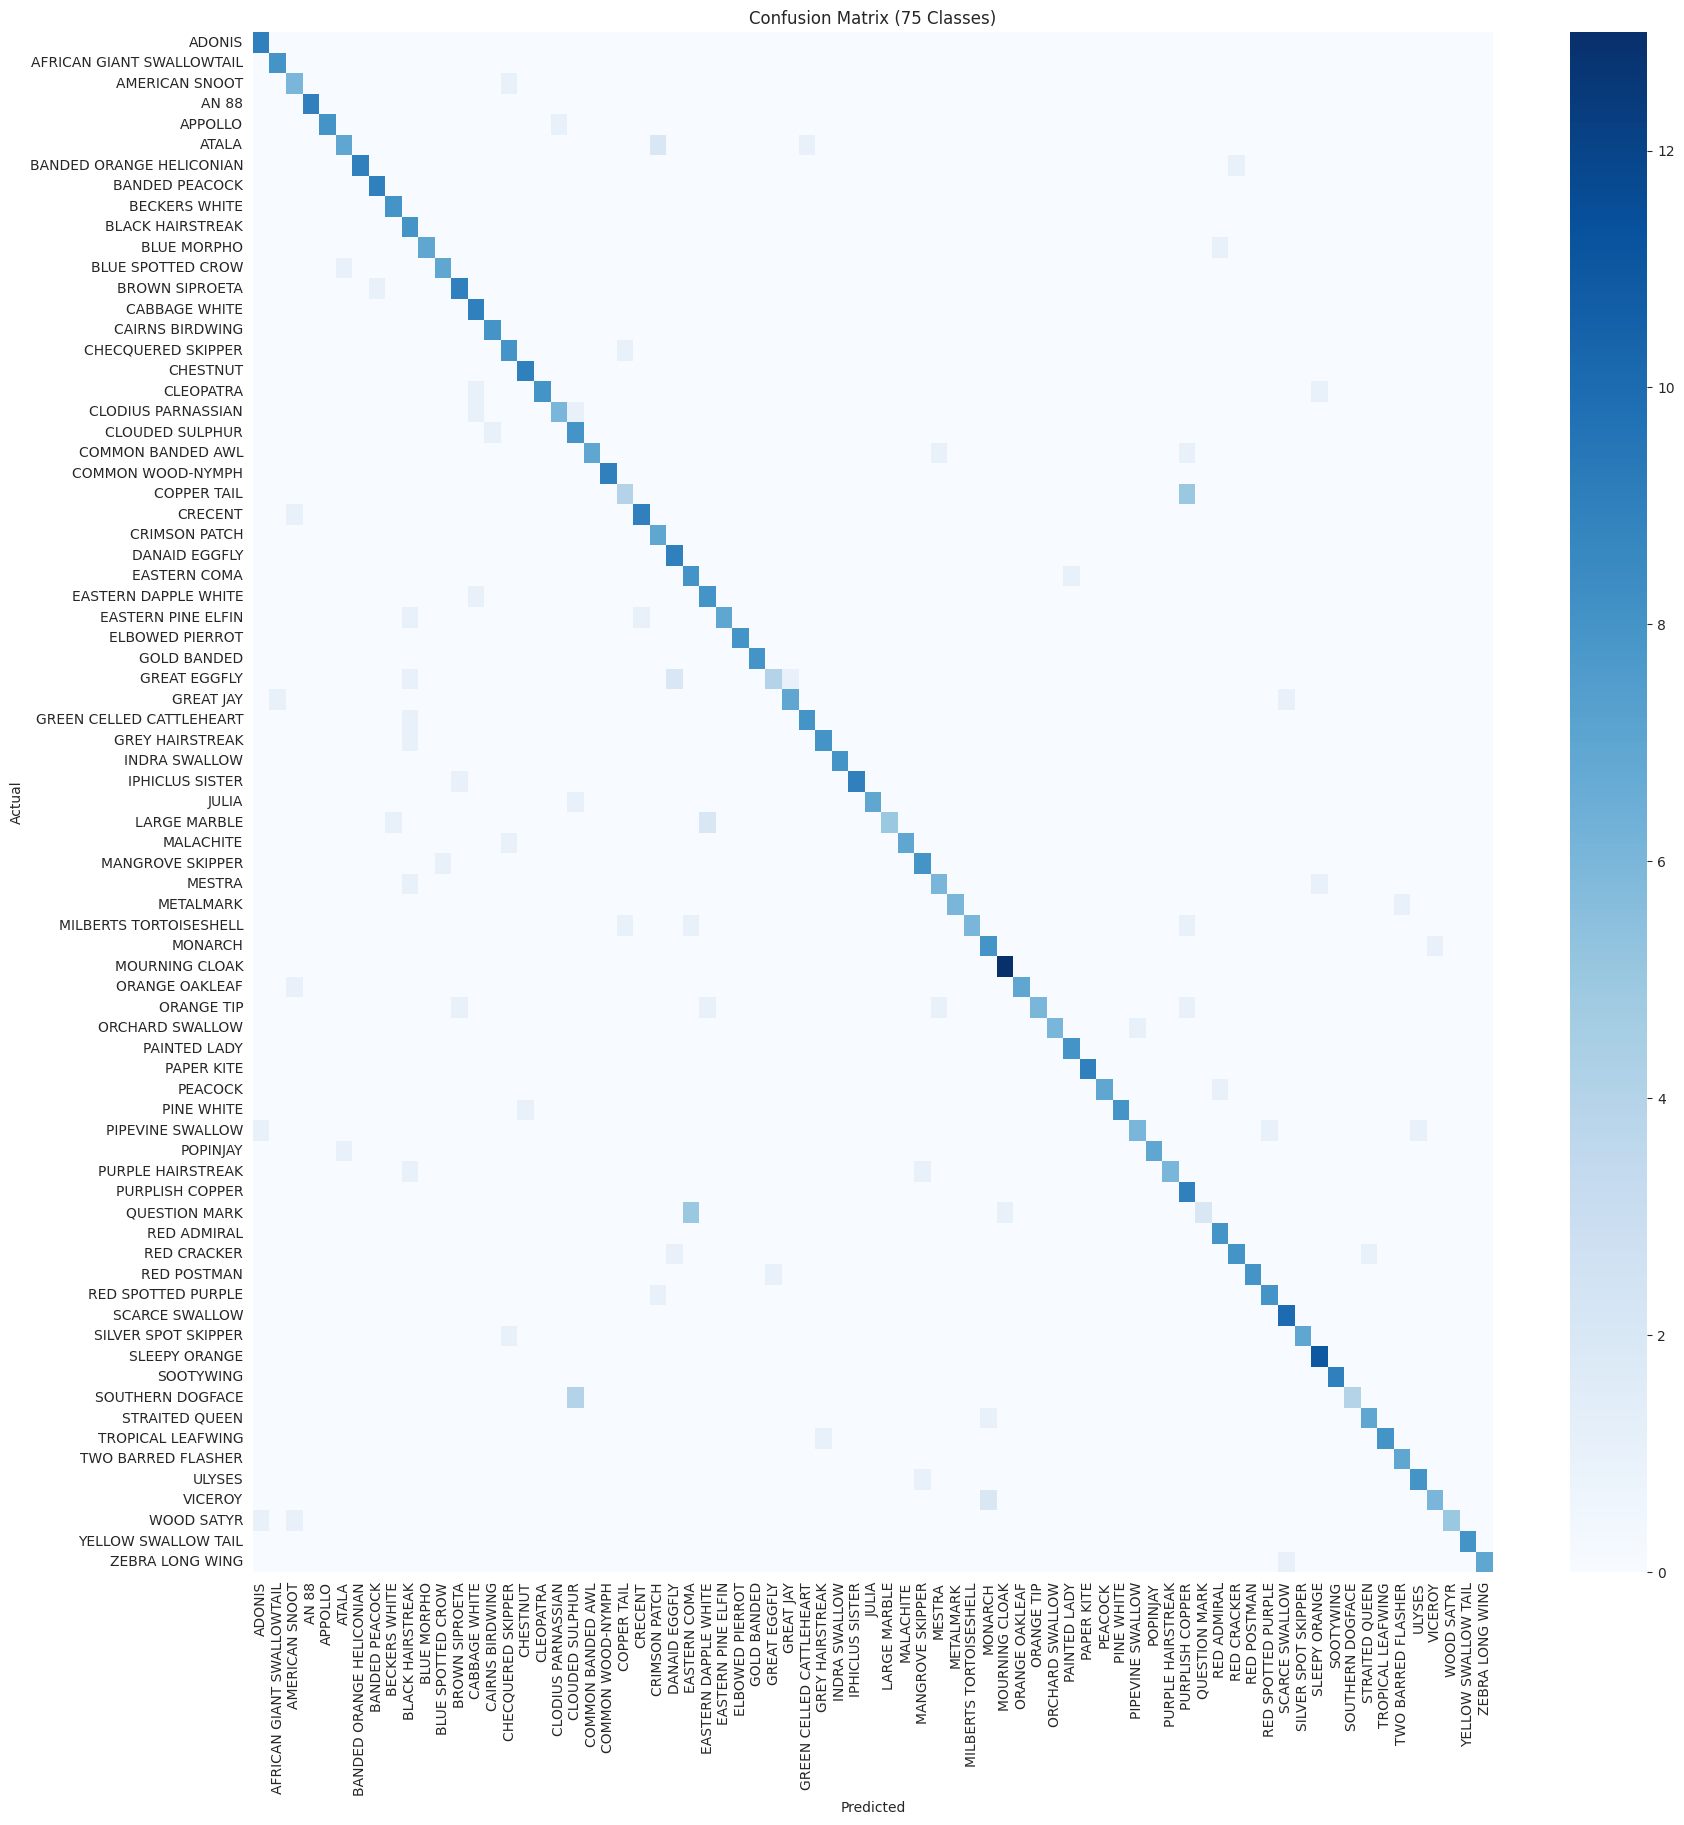


=== Classification Report ===

                           precision    recall  f1-score   support

                   ADONIS     0.8182    1.0000    0.9000         9
AFRICAN GIANT SWALLOWTAIL     0.8889    1.0000    0.9412         8
           AMERICAN SNOOT     0.6667    0.8571    0.7500         7
                    AN 88     1.0000    1.0000    1.0000         9
                  APPOLLO     1.0000    0.8889    0.9412         9
                    ATALA     0.7778    0.7000    0.7368        10
 BANDED ORANGE HELICONIAN     1.0000    0.9000    0.9474        10
           BANDED PEACOCK     0.9000    1.0000    0.9474         9
            BECKERS WHITE     0.8889    1.0000    0.9412         8
         BLACK HAIRSTREAK     0.5714    1.0000    0.7273         8
              BLUE MORPHO     1.0000    0.8750    0.9333         8
        BLUE SPOTTED CROW     0.8750    0.8750    0.8750         8
           BROWN SIPROETA     0.8182    0.9000    0.8571        10
            CABBAGE WHITE    

In [45]:
# 1. Reset generator untuk memastikan urutan data benar
test_generator.reset()

# 2. Lakukan prediksi pada seluruh data uji
raw_preds = model.predict(test_generator, verbose=1)

# 3. Ambil indeks kelas dengan probabilitas tertinggi untuk setiap sampel
y_pred = np.argmax(raw_preds, axis=1)
y_true = test_generator.classes

# 4. Mendapatkan daftar nama kelas asli secara berurutan
class_labels = list(test_generator.class_indices.keys())

# 5. Membuat dan Menampilkan Confusion Matrix
# Catatan: Karena ada 75 kelas, visualisasi heatmap akan sangat padat.
# Kita buat visualisasi berukuran besar agar tetap terbaca.
plt.figure(figsize=(20, 20))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(
    cm,
    annot=False, # Dinonaktifkan karena angka akan menumpuk pada 75 kelas
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix (75 Classes)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.show()

# 6. Menampilkan Classification Report Lengkap
print("\n=== Classification Report ===\n")
print(classification_report(y_true, y_pred, target_names=class_labels, digits=4))